# Scratchpad

In [1]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from src.model import UnconditionalConvVAE
from src.train import vae_loss, fit
from src.data import make_transform, make_loaders
import json
from src.evaluate import evaluate
from src.model_mlp import UnconditionalMLPVAE

## Open Data

Note - each test/train/val set is split into NORMAL and PNEUMONIA

In [2]:
data_dir = Path("data")

for folder in sorted(data_dir.iterdir()):
    print(folder)
    if folder.is_dir():
        for child in sorted(folder.iterdir()):
            if child.is_dir():
                print("   ", child)

data\chest_xray
    data\chest_xray\__MACOSX
    data\chest_xray\chest_xray
    data\chest_xray\test
    data\chest_xray\train
    data\chest_xray\val


## Split Counts

In [3]:
dataset_dir = Path("data/chest_xray")

print(f"{'split':<10} {'NORMAL':>10} {'PNEUMONIA':>12}")

for split in ["train", "val", "test"]:
    counts = []
    for label in ["NORMAL", "PNEUMONIA"]:
        class_dir = dataset_dir / split / label
        images = [file for file in class_dir.iterdir()
                  if file.is_file()
                  and file.suffix.lower() in [".jpeg", ".jpg", ".png"]
                  and not file.name.startswith("._")]
        counts.append(len(images))
    print(f"{split:<10} {counts[0]:>10} {counts[1]:>12}")

split          NORMAL    PNEUMONIA
train            1341         3875
val                 8            8
test              234          390


## Normal & Pneumonia Training Examples 

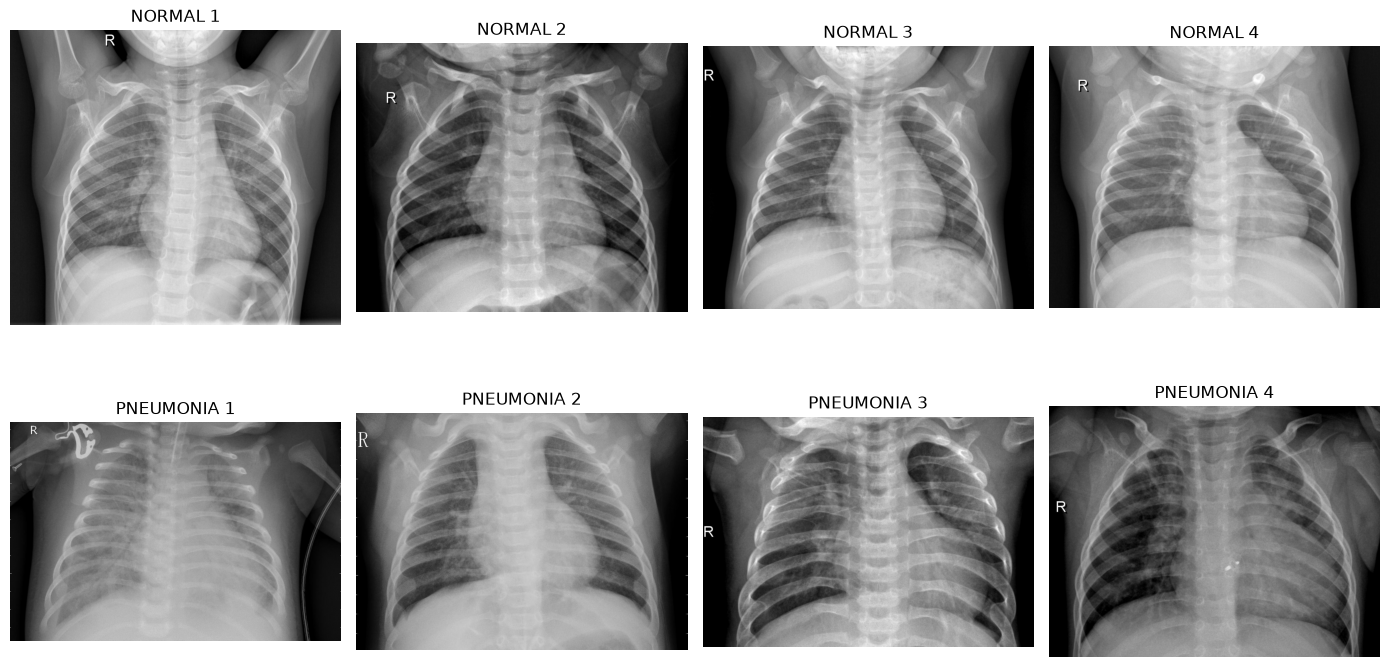

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(14, 8))
image_info = []

for row, label in enumerate(["NORMAL", "PNEUMONIA"]):
    image_paths = sorted((dataset_dir / "train" / label).glob("*.jpeg"))[:4]

    for col, image_path in enumerate(image_paths):
        example = f"{label} {col + 1}"
        with Image.open(image_path) as image:
            pixels = np.array(image)
            width, height = image.size

            image_info.append({
                "Example": example,
                "Size (W, H)": image.size,
                "Array shape": pixels.shape,
                "Mode": image.mode,
                "dtype": str(pixels.dtype),
                "Min": pixels.min(),
                "Max": pixels.max(),
                "Mean": pixels.mean(),
                "Std": pixels.std(),
                "Width / height": width / height,
            })

        axes[row, col].imshow(pixels, cmap="gray", vmin=0, vmax=255)
        axes[row, col].set_title(example)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [5]:
pd.DataFrame(image_info).set_index("Example").round(2)

,"Size (W, H)",Array shape,Mode,dtype,Min,Max,Mean,Std,Width / height
Example,,,,,,,,,
NORMAL 1,"(2090, 1858)","(1858, 2090)",L,uint8,0,255,128.91,62.30,1.12
NORMAL 2,"(1422, 1152)","(1152, 1422)",L,uint8,0,255,100.65,59.81,1.23
NORMAL 3,"(1810, 1434)","(1434, 1810)",L,uint8,0,255,121.97,68.86,1.26
NORMAL 4,"(1618, 1279)","(1279, 1618)",L,uint8,0,255,132.99,64.97,1.27
PNEUMONIA 1,"(1152, 760)","(760, 1152)",L,uint8,0,255,114.54,56.23,1.52
PNEUMONIA 2,"(1072, 768)","(768, 1072)",L,uint8,0,255,127.36,57.41,1.40
PNEUMONIA 3,"(1244, 863)","(863, 1244)",L,uint8,0,255,111.98,56.05,1.44
PNEUMONIA 4,"(1242, 940)","(940, 1242)",L,uint8,0,255,92.56,44.21,1.32


## Image sizes across the dataset

Check width, height, and aspect ratio for each split and class. 

In [6]:
size_info = []

for split in ["train", "val", "test"]:
    for label in ["NORMAL", "PNEUMONIA"]:
        class_dir = dataset_dir / split / label
        for image_path in sorted(class_dir.iterdir()):
            if (image_path.is_file()
                    and image_path.suffix.lower() in [".jpeg", ".jpg", ".png"]
                    and not image_path.name.startswith("._")):
                with Image.open(image_path) as image:
                    width, height = image.size
                size_info.append({
                    "split": split,
                    "class": label,
                    "width": width,
                    "height": height,
                    "aspect_ratio": width / height,
                })

sizes = pd.DataFrame(size_info)
sizes.groupby(["split", "class"], sort=False).agg(
    count=("width", "size"),
    width_min=("width", "min"),
    width_median=("width", "median"),
    width_max=("width", "max"),
    height_min=("height", "min"),
    height_median=("height", "median"),
    height_max=("height", "max"),
    ratio_min=("aspect_ratio", "min"),
    ratio_median=("aspect_ratio", "median"),
    ratio_max=("aspect_ratio", "max"),
).round(2)

count  width_min  width_median  width_max  height_min  \
split class                                                              
train NORMAL      1341        912        1640.0       2916         672   
      PNEUMONIA   3875        384        1168.0       2772         127   
val   NORMAL         8       1240        1446.0       1776         928   
      PNEUMONIA      8        968        1172.0       1664         592   
test  NORMAL       234        984        1762.0       2752         496   
      PNEUMONIA    390        728        1111.0       2000         344   

                 height_median  height_max  ratio_min  ratio_median  ratio_max  
split class                                                                     
train NORMAL            1328.0        2663       0.88          1.22       1.81  
      PNEUMONIA          776.0        2304       0.84          1.49       3.38  
val   NORMAL            1164.5        1416       1.12          1.22       1.39  
      PNEUMONIA          788.0        1128       1.25          1.50       1.73  
test  NORMAL            1317.5        2713       0.93          1.35       2.11  
      PNEUMONIA          736.0        1456       1.00          1.51       2.58

## Getting everything to 256 x 256

* Keep the aspect ratio: resize the shorrter side to 256, then take a 256 x 256 crop 
* Both dimensions use the same scale factor
* This avoids stretching, but it cuts off the edges of wide or tall images. 

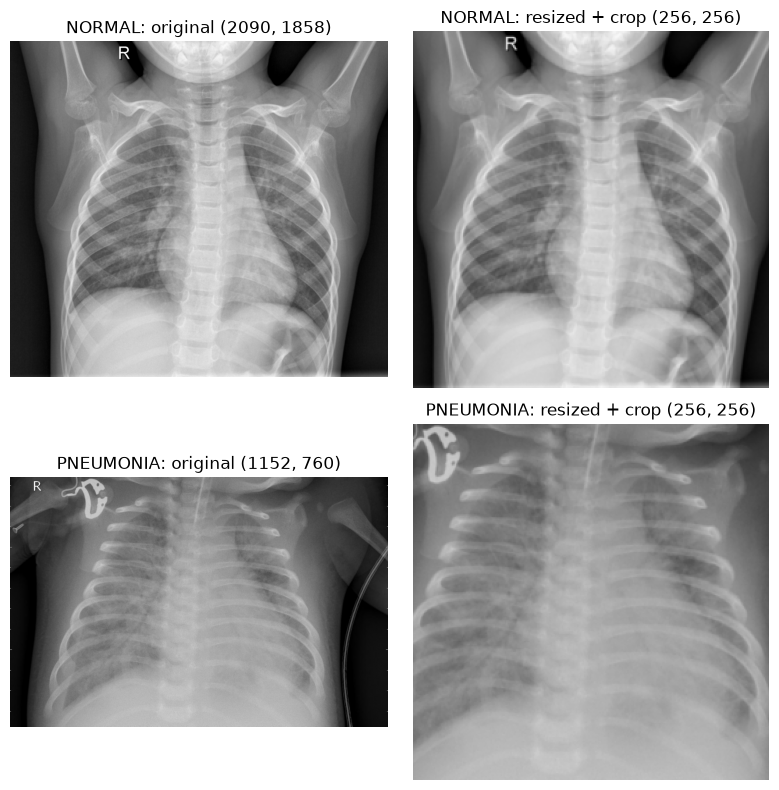

In [8]:
crop_size = 256
B = 64
num_workers = 8

image_transform = make_transform(crop_size=crop_size)

fig, axes = plt.subplots(2, 2, figsize=(8, 8))
example_tensors = []

for row, label in enumerate(["NORMAL", "PNEUMONIA"]):
    image_path = sorted((dataset_dir / "train" / label).glob("*.jpeg"))[0]
    with Image.open(image_path) as image:
        original_size = image.size
        tensor = image_transform(image)
        axes[row, 0].imshow(image, cmap="gray", vmin=0, vmax=255)
    example_tensors.append(tensor)
    axes[row, 0].set_title(f"{label}: original {original_size}")
    axes[row, 1].imshow(tensor[0], cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title(f"{label}: resized + crop ({crop_size}, {crop_size})")
    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## VAE design

`UnconditionalConvVAE`: 
* Has grayscale single channel input/output at 256 x 256
* configurable latent space; the newest experiment uses 256 coordinates
* NORMAL and PNEUMONIA images share the same model - class labels neglected. Just aiming to generate chest x-rays, not necssarily distinguish them
* B is batch size

Encoder: five convolutions, each with kernel size 4, stride 2, padding 1, and ReLU.

| Stage | Output shape |
| --- | --- |
| Input | (B, 1, 256, 256) |
| Conv1 | (B, 32, 128, 128) |
| Conv2 | (B, 64, 64, 64) |
| Conv3 | (B, 128, 32, 32) |
| Conv4 | (B, 256, 16, 16) |
| Conv5 | (B, 256, 8, 8) |
| Flatten | (B, 16,384) |
| Separate linear heads: means and logvar | (B, latent_dim) each |
| Sampled latent vector z | (B, latent_dim) |

Decoder: a linear layer expands z to 16,384 features, reshaped to (B, 256, 8, 8). Five transposed convolutions use kernel size 4, stride 2, and padding 1:

| Stage | Output shape |
| --- | --- |
| Latent vector z | (B, latent_dim) |
| Linear | (B, 16,384) |
| Reshape | (B, 256, 8, 8) |
| Transposed Conv1 | (B, 256, 16, 16) |
| Transposed Conv2 | (B, 128, 32, 32) |
| Transposed Conv3 | (B, 64, 64, 64) |
| Transposed Conv4 | (B, 32, 128, 128) |
| Transposed Conv5 | (B, 1, 256, 256) |

Total parameters: 16,075,457 for latent size 256 (previously 6,637,889 for 64; 8,210,817 for 96).


In [9]:
latent_dim = 256
model = UnconditionalConvVAE(latent_dim=latent_dim)

# Just checking shapes here - no training yet.
x = torch.stack(example_tensors)
model.eval()
with torch.no_grad():
    logits, means, logvar = model(x)
    reconstructions = logits.sigmoid()
    generated = model.sample(2)

assert logits.shape == x.shape == (2, 1, 256, 256)
assert means.shape == logvar.shape == (2, latent_dim)
assert generated.shape == (2, 1, 256, 256)
assert torch.isfinite(logits).all() and torch.isfinite(generated).all()

print("Input:                ", tuple(x.shape))
print("means &  logvar:      ", tuple(means.shape), tuple(logvar.shape))
print("Reconstruction Output:", tuple(reconstructions.shape))
print("Generated:            ", tuple(generated.shape))
print("Param Count:          ", f"{sum(p.numel() for p in model.parameters()):,}")

Input:                 (2, 1, 256, 256)
means &  logvar:       (2, 256) (2, 256)
Reconstruction Output: (2, 1, 256, 256)
Generated:             (2, 1, 256, 256)
Param Count:           16,075,457


In [10]:
loss, reconstruction_loss, kl_loss = vae_loss(logits, x, means, logvar)

print(f"Reconstruction: {reconstruction_loss.item():.2f}")
print(f"KL:             {kl_loss.item():.2f}")
print(f"Total:          {loss.item():.2f}")

Reconstruction: 2116.65
KL:             0.01
Total:          2116.66


## Data loaders
Each image is: 
* Converted to grayscale
* Resized with the same scale factor for width and height
* Center-cropped
* Converted to a float tensor in [0,1]
* Only train is shuffled
* Keep the last group even if it has fewer than B images (val set is tiny)
* Use 8 persistent workers, pinned memory, and non-blocking GPU transfers for faster trainin

In [11]:
loaders = make_loaders(dataset_dir, crop_size=crop_size, B=B, num_workers=num_workers)
train_loader = loaders["train"]
val_loader = loaders["val"]
test_loader = loaders["test"]

for split, loader in loaders.items():
    print(f"{split}: {len(loader.dataset)} images, {len(loader)} groups of up to {B}")

images, labels = next(iter(train_loader))
assert images.shape == (min(B, len(train_loader.dataset)), 1, crop_size, crop_size)
assert images.dtype == torch.float32
assert torch.isfinite(images).all()
assert 0 <= images.min() <= images.max() <= 1
print("Training tensor:", tuple(images.shape))
print("Pixel range:", images.min().item(), "to", images.max().item())

train: 5216 images, 82 groups of up to 64
val: 16 images, 1 groups of up to 64
test: 624 images, 10 groups of up to 64


Training tensor: (64, 1, 256, 256)
Pixel range: 0.0 to 1.0


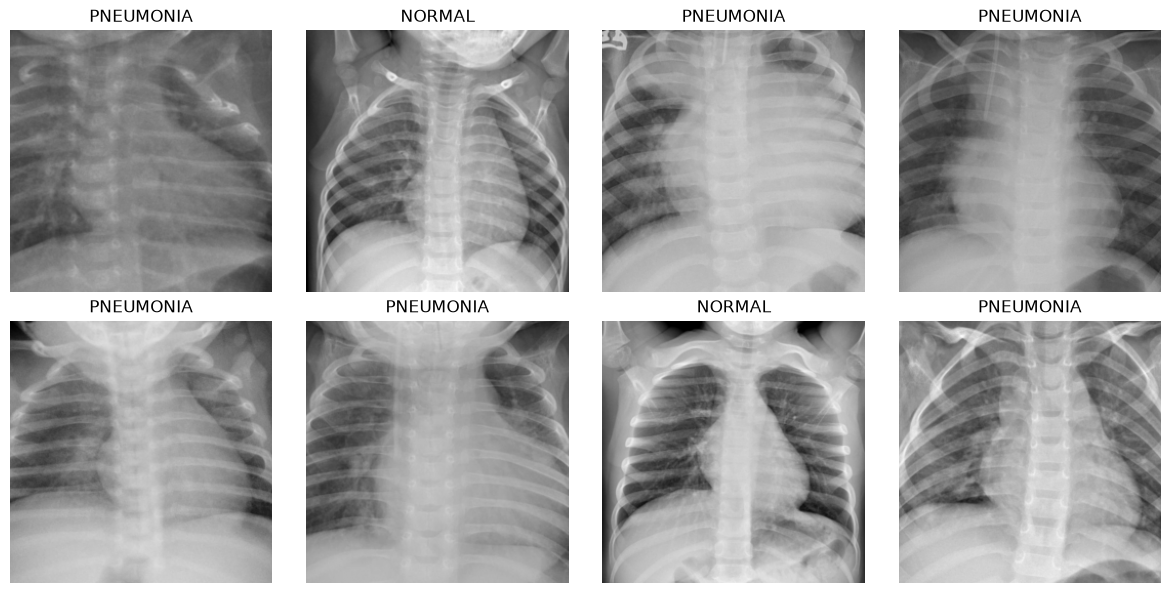

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for index, ax in enumerate(axes.flat):
    if index < len(images):
        ax.imshow(images[index, 0], cmap="gray", vmin=0, vmax=1)
        ax.set_title(train_loader.dataset.classes[labels[index].item()])
    ax.axis("off")
plt.tight_layout()
plt.show()

## Completed 256 x 256 runs

| Latent size | B | Best epoch | Validation loss | FID (lower) | IS (higher) |
| --- | --- | --- | --- | --- | --- |
| 64 | 64 | 20 | 315.07 | 431.78 | 1.368 |
| 128 | 32 | 19 | 308.90 | 427.93 | 1.538 |
| 96 | 64 | 20 | 325.43 | 432.66 | 1.350 |
| 256 | 64 | 20 | 355.77 | 439.01 | 1.310 |

The 128-dimensional run used B = 32, so it had about twice as many optimizer steps per epoch. These are single runs on a small validation set; differences do not establish an optimal latent size.

## Training

The convolutional runs below use 256 x 256 inputs and transposed-convolution decoders. The latent-64, latent-96, and latent-256 runs use B = 64, eight persistent workers, 20 epochs, Adam at 1e-4, seed 42, and the same MSE + KL objective.

Training is disabled in the notebook; these cells inspect saved results. The later MLP sections contain the final-report model.

In [13]:
run_dirs = {size: Path(f"outputs/vae_256_B64_Z{size}_run01") for size in [64, 96, 256]}
results_dir = run_dirs[256]  # Choose which run to inspect below.
epochs = 20
learning_rate = 1e-4
seed = 42
RUN_TRAINING = False

if RUN_TRAINING:
    for size, run_dir in run_dirs.items():
        torch.manual_seed(seed)
        model = UnconditionalConvVAE(latent_dim=size)
        loaders = make_loaders(dataset_dir, crop_size=crop_size, B=B, seed=seed,
                               num_workers=num_workers)
        history = fit(model, loaders["train"], loaders["val"], run_dir,
                      epochs=epochs, learning_rate=learning_rate, seed=seed)
else:
    print("Training disabled in this cell. Reading:", results_dir)

Training disabled in this cell. Reading: outputs\vae_256_B64_Z256_run01


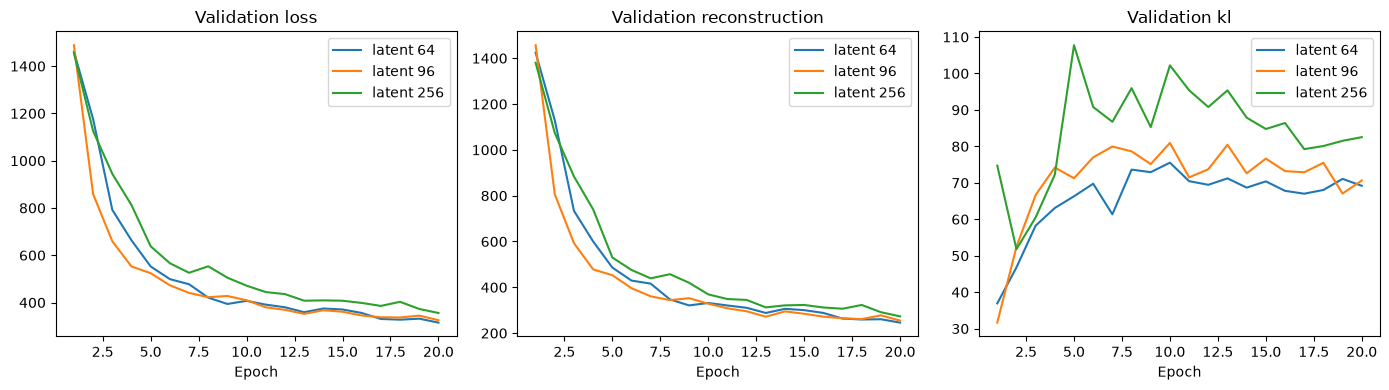

,Latent size,B,Best epoch,Best validation loss
0,64,64,20,315.07
1,96,64,20,325.43
2,256,64,20,355.77


In [14]:
comparison = []
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for size, path in run_dirs.items():
    run_history = pd.read_csv(path / "history.csv")
    saved = torch.load(path / "best.pt", map_location="cpu", weights_only=True)
    comparison.append({"Latent size": size, "B": saved["config"]["B"],
                       "Best epoch": saved["epoch"], "Best validation loss": saved["val_loss"]})
    for ax, metric in zip(axes, ["loss", "reconstruction", "kl"]):
        ax.plot(run_history["epoch"], run_history[f"val_{metric}"], label=f"latent {size}")
        ax.set_title(f"Validation {metric}")
        ax.set_xlabel("Epoch")
        ax.legend()
plt.tight_layout()
plt.show()
pd.DataFrame(comparison).round(2)

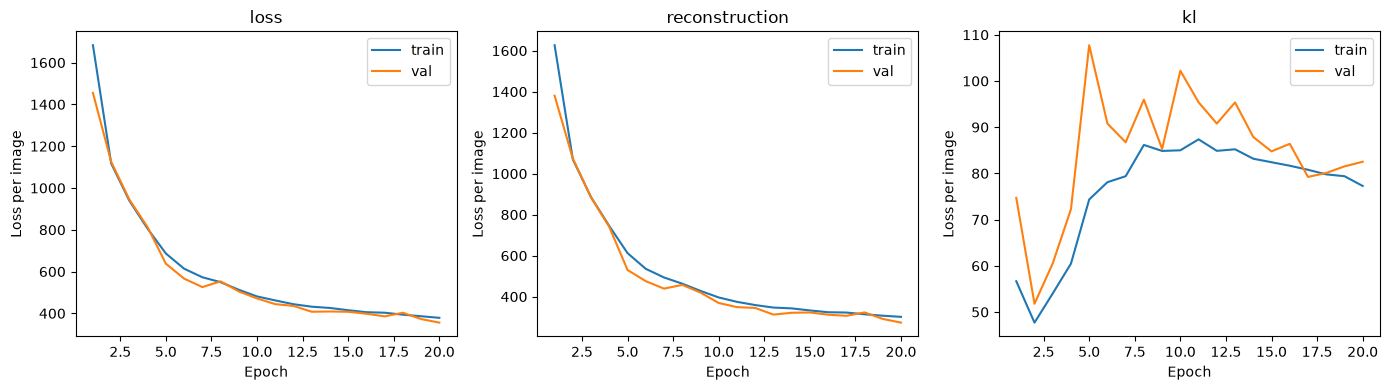

,epoch,train_loss,train_reconstruction,train_kl,val_loss,val_reconstruction,val_kl,seconds
15,16,405.629979,323.971455,81.658523,398.365601,311.964935,86.400650,5.284424
16,17,403.221962,322.442403,80.779559,385.747803,306.512421,79.235374,5.386995
17,18,393.769724,313.979767,79.789955,403.074310,322.983765,80.090546,5.315281
18,19,386.330876,306.939660,79.391216,372.822174,291.301727,81.520447,5.164473
19,20,378.728243,301.446978,77.281265,355.772858,273.253937,82.518913,5.170637


In [15]:
history = pd.read_csv(results_dir / "history.csv")
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, ["loss", "reconstruction", "kl"]):
    ax.plot(history["epoch"], history[f"train_{metric}"], label="train")
    ax.plot(history["epoch"], history[f"val_{metric}"], label="val")
    ax.set_title(metric)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss per image")
    ax.legend()
plt.tight_layout()
plt.show()
history.tail()

Saved run B: 64
Best validation epoch: 20


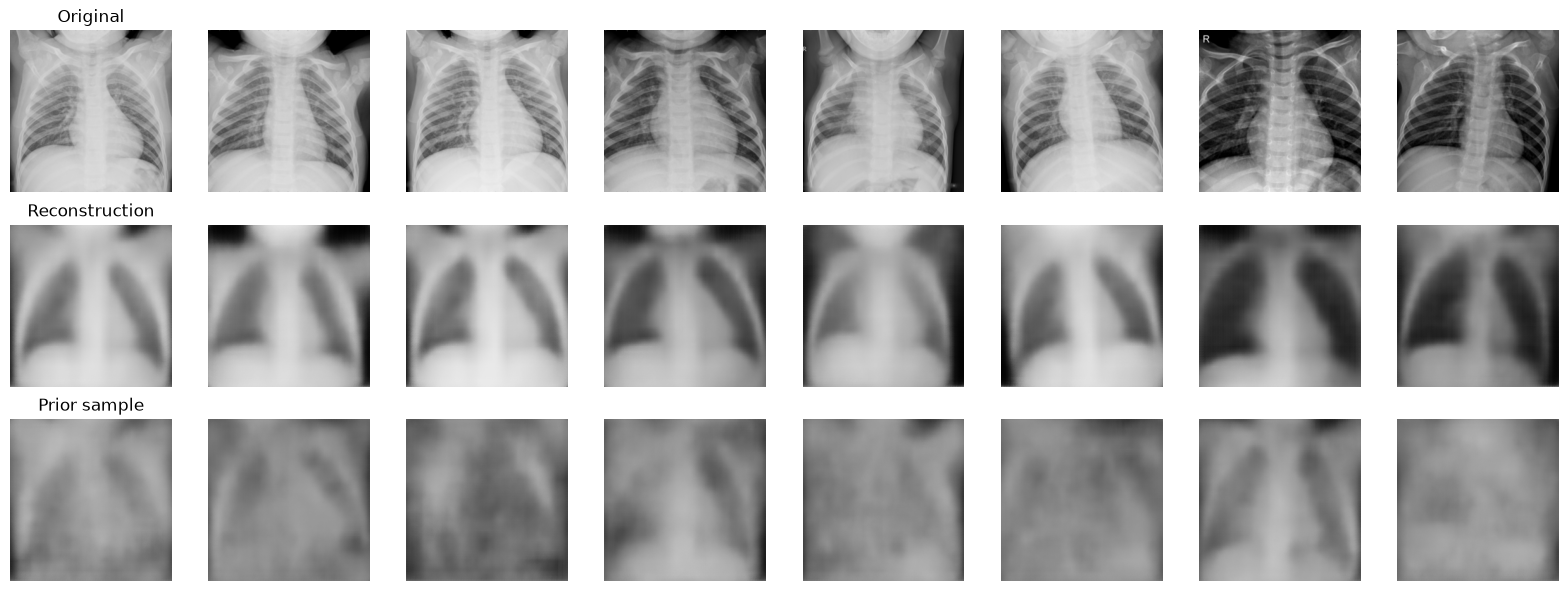

In [16]:
best_checkpoint = torch.load(results_dir / "best.pt", map_location="cpu", weights_only=True)
trained_model = UnconditionalConvVAE(best_checkpoint["config"]["latent_dim"])
trained_model.load_state_dict(best_checkpoint["model"])
trained_model.eval()
print("Saved run B:", best_checkpoint["config"]["B"])
print("Best validation epoch:", best_checkpoint["epoch"])

originals, _ = next(iter(val_loader))
originals = originals[:8]
with torch.no_grad():
    means, _ = trained_model.encode(originals)
    reconstructed = trained_model.decode(means).sigmoid()
    z = torch.randn(8, trained_model.latent_dim,
                    generator=torch.Generator().manual_seed(seed))
    samples = trained_model.decode(z).sigmoid()

fig, axes = plt.subplots(3, 8, figsize=(16, 6))
for row, (tensors, title) in enumerate([
    (originals, "Original"), (reconstructed, "Reconstruction"), (samples, "Prior sample")
]):
    for col in range(8):
        axes[row, col].imshow(tensors[col, 0], cmap="gray", vmin=0, vmax=1)
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_title(title)
plt.tight_layout()
plt.show()

## Test FID and Inception Score

In [17]:
evaluation_device = "cuda" if torch.cuda.is_available() else "cpu"
score_rows = []
for size, path in run_dirs.items():
    saved = torch.load(path / "best.pt", map_location="cpu", weights_only=True)
    evaluated_model = UnconditionalConvVAE(latent_dim=size)
    evaluated_model.load_state_dict(saved["model"])
    score_path = path / "test_scores.json"
    if score_path.exists():
        scores = json.loads(score_path.read_text())
    else:
        scores = evaluate(evaluated_model, test_loader, seed=2026, device=evaluation_device)
    scores["checkpoint"] = str(path / "best.pt")
    scores["checkpoint_epoch"] = saved["epoch"]
    scores["training_B"] = saved["config"]["B"]
    scores["latent_dim"] = size
    (path / "test_scores.json").write_text(json.dumps(scores, indent=2))
    score_rows.append(scores)
    del evaluated_model
pd.DataFrame(score_rows).loc[:, ["latent_dim", "FID", "IS", "real_images",
                               "generated_images", "checkpoint_epoch", "training_B"]]

Evaluated 64/624 images


Evaluated 128/624 images


Evaluated 192/624 images


Evaluated 256/624 images


Evaluated 320/624 images


Evaluated 384/624 images


Evaluated 448/624 images


Evaluated 512/624 images


Evaluated 576/624 images


Evaluated 624/624 images


,latent_dim,FID,IS,real_images,generated_images,checkpoint_epoch,training_B
0,64,431.780938,1.367638,624,624,20,64
1,96,432.664100,1.350358,624,624,20,64
2,256,439.009976,1.309925,624,624,20,64


## Fully connected VAE: four hidden layers

Completed all 40 epochs.

Use `UnconditionalMLPVAE` from `src/model_mlp.py`. Both encoder and decoder have four hidden layers of width 512, with ReLU after each. The latent vector has 256 coordinates.

| Encoder stage | Output shape |
| --- | --- |
| Input | (B, 1, 256, 256) |
| Flatten | (B, 65,536) |
| Hidden 1 | (B, 512) |
| Hidden 2 | (B, 512) |
| Hidden 3 | (B, 512) |
| Hidden 4 | (B, 512) |
| Separate means and logvar heads | (B, 256) each |
| Sample z | (B, 256) |

| Decoder stage | Output shape |
| --- | --- |
| z | (B, 256) |
| Hidden 1 | (B, 512) |
| Hidden 2 | (B, 512) |
| Hidden 3 | (B, 512) |
| Hidden 4 | (B, 512) |
| Output logits | (B, 65,536) |
| Reshape | (B, 1, 256, 256) |

The network has 69,145,088 parameters. Sigmoid converts the output logits to intensities. Use the fixed-variance summed MSE + KL objective, with KL coefficient one.

Train for 40 epochs, Adam at 1e-4, B = 64, eight persistent workers, seed 42. Keep the same preprocessing: grayscale, proportional resize, center crop to 256 x 256, float32 in [0,1]. No normalization to [-1,1] or target clamping. Image exports remain every five epochs. The run is launched separately; the cells below only read its results.

This changes both architecture and training duration relative to the 20-epoch convolutional baselines, so it is not a comparison of architecture alone.

Best epoch: 40
Parameters: 69,145,088


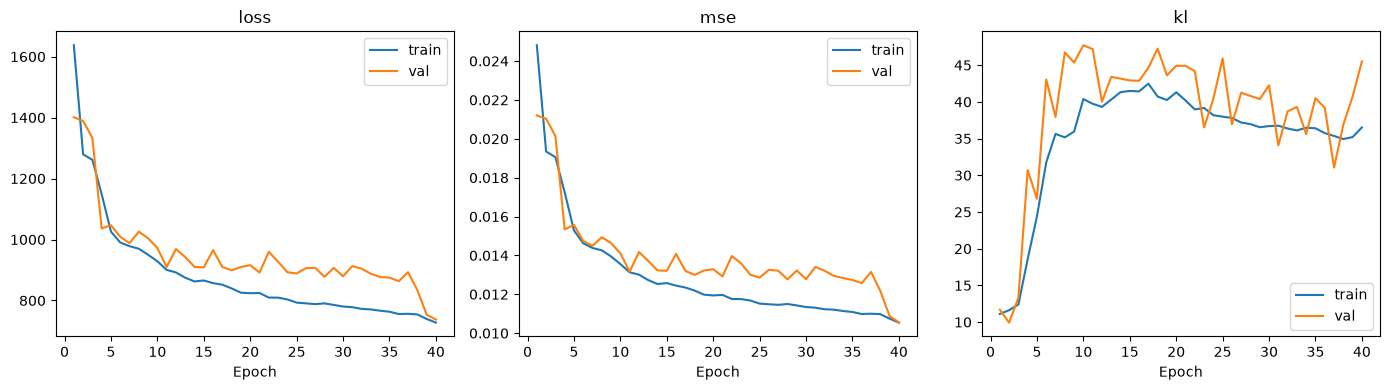

,epoch,train_loss,train_reconstruction,train_kl,train_mse,val_loss,val_reconstruction,val_kl,val_mse,seconds,pixel_variance
35,36,755.657756,719.917705,35.740054,0.010985,863.387939,824.183350,39.204567,0.012576,6.319041,0.5
36,37,756.364169,721.013091,35.351079,0.011002,892.924927,861.872681,31.052246,0.013151,5.168566,0.5
37,38,754.345352,719.416016,34.929335,0.010977,834.353516,797.466675,36.886810,0.012168,4.982427,0.5
38,39,739.458541,704.258163,35.200378,0.010746,753.736450,713.015625,40.720814,0.010880,5.228903,0.5
39,40,727.414863,690.899783,36.515080,0.010542,737.365723,691.855408,45.510338,0.010557,5.095719,0.5


In [3]:
mlp_run_dir = Path("outputs/vae_256_mlp4_B64_Z256_run01")
mlp_history = pd.read_csv(mlp_run_dir / "history.csv")
mlp_checkpoint = torch.load(mlp_run_dir / "best.pt", map_location="cpu", weights_only=True)
mlp_model = UnconditionalMLPVAE().eval()
mlp_model.load_state_dict(mlp_checkpoint["model"])
print("Best epoch:", mlp_checkpoint["epoch"])
print("Parameters:", f"{sum(p.numel() for p in mlp_model.parameters()):,}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for split in ["train", "val"]:
    for ax, metric in zip(axes, ["loss", "mse", "kl"]):
        ax.plot(mlp_history["epoch"], mlp_history[f"{split}_{metric}"], label=split)
        ax.set_title(metric)
        ax.set_xlabel("Epoch")
        ax.legend()
plt.tight_layout()
plt.show()
mlp_history.tail()

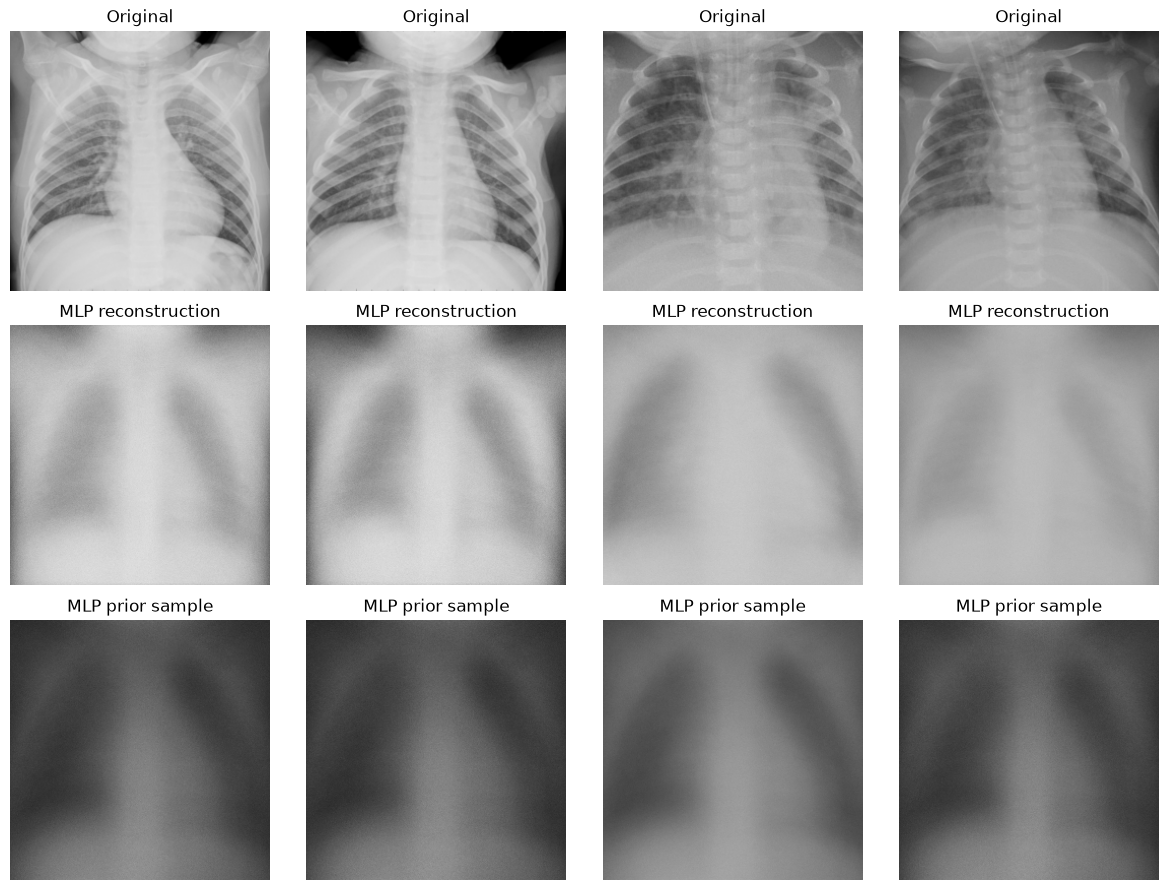

In [4]:
originals, _ = next(iter(val_loader))
originals = originals[[0, 1, 8, 9]]
with torch.no_grad():
    mlp_means, _ = mlp_model.encode(originals)
    mlp_reconstructed = mlp_model.decode(mlp_means).sigmoid()
    z = torch.randn(4, mlp_model.latent_dim, generator=torch.Generator().manual_seed(2026))
    mlp_samples = mlp_model.decode(z).sigmoid()
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for row, (tensors, title) in enumerate([
    (originals, "Original"), (mlp_reconstructed, "MLP reconstruction"), (mlp_samples, "MLP prior sample")
]):
    for col in range(4):
        axes[row, col].imshow(tensors[col, 0], cmap="gray", vmin=0, vmax=1)
        axes[row, col].set_title(title)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

In [5]:
mlp_score_path = mlp_run_dir / "test_scores.json"
if mlp_score_path.exists():
    mlp_scores = json.loads(mlp_score_path.read_text())
else:
    mlp_scores = evaluate(mlp_model, test_loader, seed=2026)
    mlp_scores["checkpoint"] = str(mlp_run_dir / "best.pt")
    mlp_scores["checkpoint_epoch"] = mlp_checkpoint["epoch"]
    mlp_scores["latent_dim"] = mlp_model.latent_dim
    mlp_scores["model_type"] = "UnconditionalMLPVAE"
    mlp_score_path.write_text(json.dumps(mlp_scores, indent=2))
pd.DataFrame([mlp_scores]).loc[:, ["FID", "IS", "real_images", "generated_images", "checkpoint_epoch"]]

Evaluated 64/624 images


Evaluated 128/624 images


Evaluated 192/624 images


Evaluated 256/624 images


Evaluated 320/624 images


Evaluated 384/624 images


Evaluated 448/624 images


Evaluated 512/624 images


Evaluated 576/624 images


Evaluated 624/624 images


,FID,IS,real_images,generated_images,checkpoint_epoch
0,447.687592,1.013678,624,624,40


## MLP outcome

Completed all 40 epochs at 1e-4, B = 64, latent size 256, with the original 256 preprocessing and fixed-variance MSE + KL objective. Four hidden layers of width 512 in both encoder and decoder; 69,145,088 parameters.

Best checkpoint: epoch 40. Validation MSE per pixel: 0.010557. Test FID: 447.69; IS: 1.014, using 624 real images and 624 prior samples with the same evaluation convention as earlier runs.

This run did not solve the visual-quality problem. Reconstructions remain blurry and the displayed prior samples have little variation. Its validation reconstruction error is higher than the convolutional baselines, despite the longer training run. Training is finished.

## MLP: latent size 128, learning rate 1e-3

Completed all 40 epochs.

Repeat the four-hidden-layer MLP at latent_dim = 128 and Adam learning rate = 0.001, for 40 epochs. B = 64, eight workers, seed 42, fixed-variance MSE + KL, and the same 256 preprocessing. No architecture changes beyond latent size.

The previous MLP used latent size 256 and learning rate 0.0001, so this comparison changes both latent size and learning rate. Keep its results separately. This run is launched through `src/run_experiments.py`; the cells below only inspect saved results.

Best epoch: 35
Parameters: 68,948,224


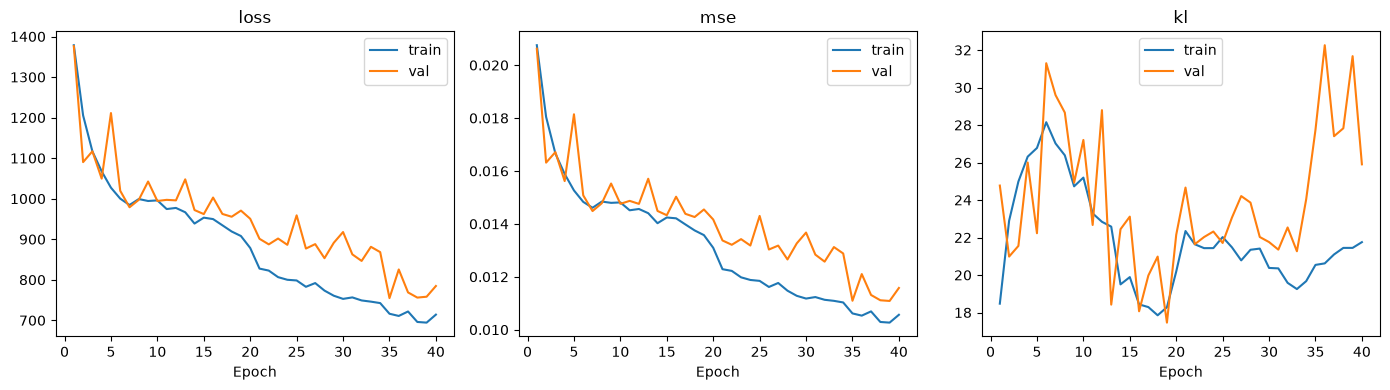

,epoch,train_loss,train_reconstruction,train_kl,train_mse,val_loss,val_reconstruction,val_kl,val_mse,seconds,pixel_variance
35,36,710.828532,690.207729,20.620805,0.010532,825.438721,793.180725,32.257988,0.012103,6.020709,0.5
36,37,721.821009,700.723806,21.097202,0.010692,768.807800,741.404053,27.403769,0.011313,5.749258,0.5
37,38,695.975443,674.528965,21.446480,0.010292,756.100159,728.273682,27.826481,0.011113,5.686563,0.5
38,39,694.343251,672.896098,21.447152,0.010268,758.246582,726.572693,31.673897,0.011087,5.837943,0.5
39,40,714.076251,692.322231,21.754021,0.010564,784.676453,758.772705,25.903753,0.011578,5.596467,0.5


In [3]:
mlp128_dir = Path("outputs/vae_256_mlp4_B64_Z128_lr0p001_run01")
mlp128_history = pd.read_csv(mlp128_dir / "history.csv")
mlp128_checkpoint = torch.load(mlp128_dir / "best.pt", map_location="cpu", weights_only=True)
mlp128_model = UnconditionalMLPVAE(latent_dim=128).eval()
mlp128_model.load_state_dict(mlp128_checkpoint["model"])
print("Best epoch:", mlp128_checkpoint["epoch"])
print("Parameters:", f"{sum(p.numel() for p in mlp128_model.parameters()):,}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for split in ["train", "val"]:
    for ax, metric in zip(axes, ["loss", "mse", "kl"]):
        ax.plot(mlp128_history["epoch"], mlp128_history[f"{split}_{metric}"], label=split)
        ax.set_title(metric)
        ax.set_xlabel("Epoch")
        ax.legend()
plt.tight_layout()
plt.show()
mlp128_history.tail()

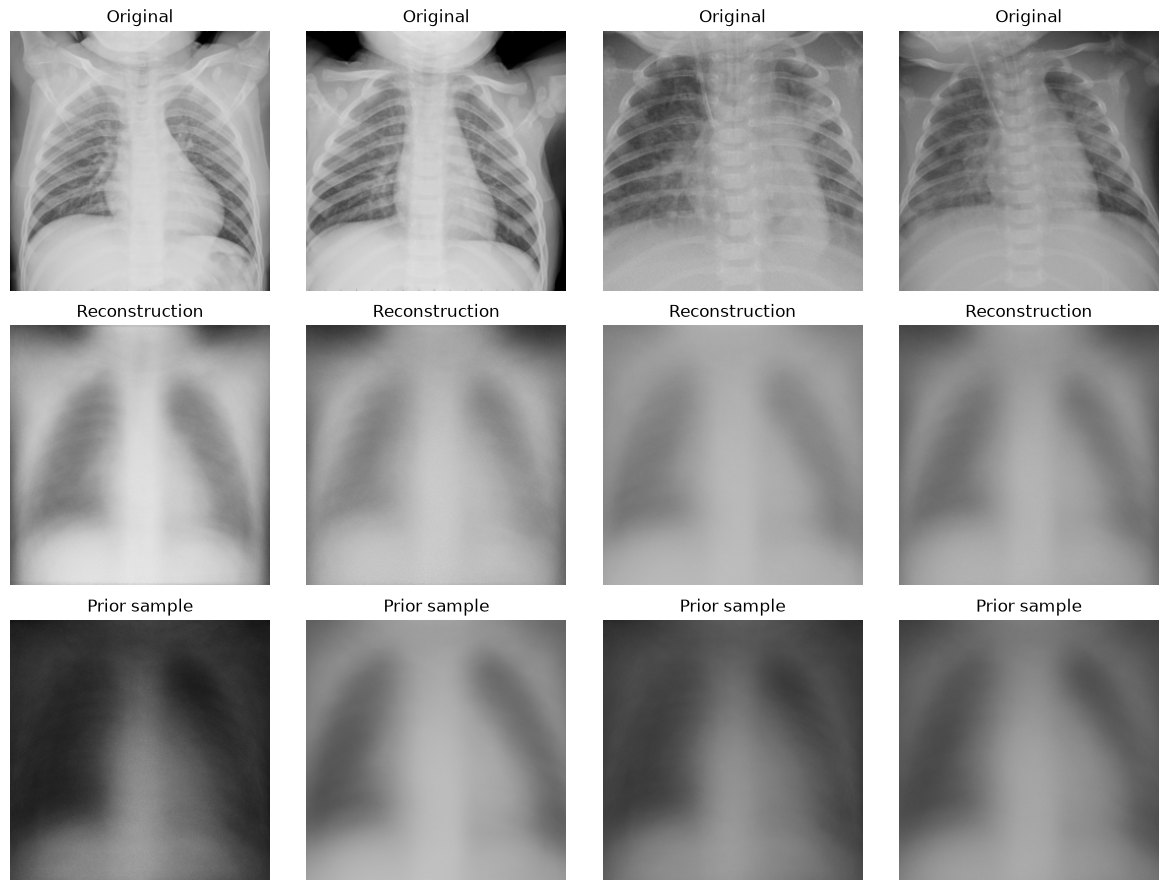

In [4]:
originals, _ = next(iter(val_loader))
originals = originals[[0, 1, 8, 9]]
with torch.no_grad():
    means, _ = mlp128_model.encode(originals)
    reconstructed = mlp128_model.decode(means).sigmoid()
    z = torch.randn(4, 128, generator=torch.Generator().manual_seed(2026))
    generated = mlp128_model.decode(z).sigmoid()
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for row, (tensors, title) in enumerate([
    (originals, "Original"), (reconstructed, "Reconstruction"), (generated, "Prior sample")
]):
    for col in range(4):
        axes[row, col].imshow(tensors[col, 0], cmap="gray", vmin=0, vmax=1)
        axes[row, col].set_title(title)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

In [5]:
mlp128_score_path = mlp128_dir / "test_scores.json"
if mlp128_score_path.exists():
    mlp128_scores = json.loads(mlp128_score_path.read_text())
else:
    mlp128_scores = evaluate(mlp128_model, test_loader, seed=2026)
    mlp128_scores["checkpoint"] = str(mlp128_dir / "best.pt")
    mlp128_scores["checkpoint_epoch"] = mlp128_checkpoint["epoch"]
    mlp128_scores["latent_dim"] = 128
    mlp128_scores["learning_rate"] = 1e-3
    mlp128_scores["model_type"] = "UnconditionalMLPVAE"
    mlp128_score_path.write_text(json.dumps(mlp128_scores, indent=2))
pd.DataFrame([mlp128_scores]).loc[:, ["FID", "IS", "real_images", "generated_images", "checkpoint_epoch"]]

Evaluated 64/624 images


Evaluated 128/624 images


Evaluated 192/624 images


Evaluated 256/624 images


Evaluated 320/624 images


Evaluated 384/624 images


Evaluated 448/624 images


Evaluated 512/624 images


Evaluated 576/624 images


Evaluated 624/624 images


,FID,IS,real_images,generated_images,checkpoint_epoch
0,427.610168,1.072586,624,624,35


## MLP comparison after 40 epochs

Both runs use B = 64, the same four 512-unit hidden layers per side, seed 42, fixed-variance MSE + KL, and unchanged 256 preprocessing.

| Latent size | Learning rate | Best epoch | Validation MSE / pixel | FID | IS |
| --- | --- | --- | --- | --- | --- |
| 256 | 0.0001 | 40 | 0.010557 | 447.69 | 1.014 |
| 128 | 0.001 | 35 | 0.011094 | 427.61 | 1.073 |

The latest run has better FID/IS but slightly higher validation reconstruction error. The displayed reconstructions and samples remain blurry and still lack fine rib detail. Since latent size and learning rate changed together, this does not isolate the learning-rate effect. All 40 epochs finished; training is stopped.

## Final

MLP run with latent size 128, lr = 0.001, B = 64, and 40 epochs.

* Epoch 35 has the lowest total val loss, so use this checkpoint for the final results (FID = 427.61, IS = 1.073). 
    * Reconstructions get the overall chest structure, but lose the finer rib detail. The generated samples are still blurry.
* Epoch 15 has the best-looking samples from the saved grids. The rib-like detail is more visible, though still faint/blurry. 

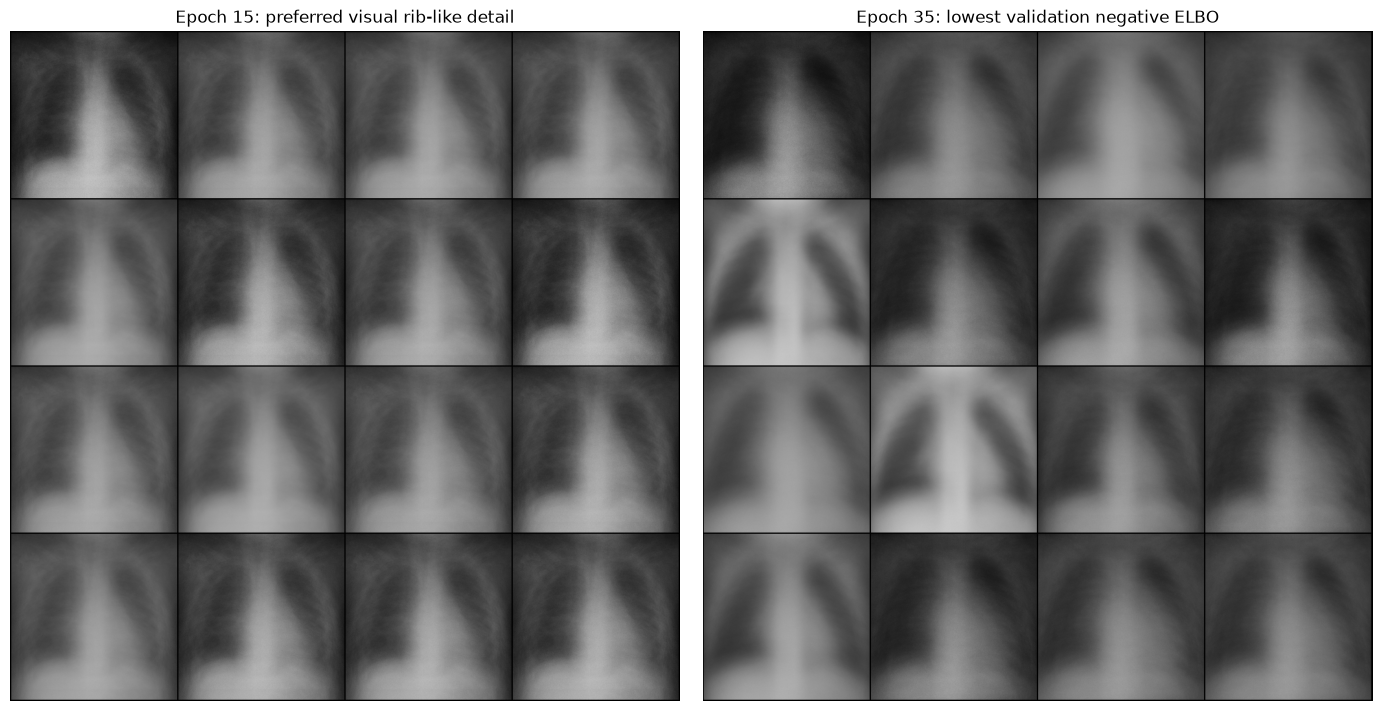

In [11]:
final_run_dir = Path("outputs/vae_256_mlp4_B64_Z128_lr0p001_run01")
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, epoch, title in zip(axes, [15, 35], [
    "Epoch 15: preferred visual rib-like detail",
    "Epoch 35: lowest validation negative ELBO",
]):
    with Image.open(final_run_dir / f"samples_{epoch:02d}.png") as image:
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()